# Week 10: K-Means Clustering  
### Victor Vasquez Gil | Boston University | Integrated Capstone
DX799 — Module C | Week 10

## 1. What I want to find out
For my capstone, I want to understand which loan and borrower characteristics could help a lending team review risk. This week, I am looking for groups of loans with similar financial profiles. I want to see whether those groups are clearly separated and whether their repayment outcomes differ.

I use K-means to form the groups. Unlike a classifier, K-means does not learn from the charge-off label. I keep loan_status out of the clustering and bring it back only after the features, preprocessing, and number of clusters have been fixed. A cluster number is a group label, not a prediction that a borrower will repay or charge off.

I compare the elbow method and silhouette scores, check how scaling changes the groups, and look at whether the grouping holds up on loans that were not used to fit it. What matters to me is whether I can explain the differences between the groups and support that explanation with the results.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, HTML, Markdown, Image
from threadpoolctl import threadpool_limits
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.exceptions import ConvergenceWarning

SEED = 42
SAMPLE_SIZE = 50_000
ANALYSIS_SIZE = 10_000
CHUNK_SIZE = 25_000
EXPECTED_SOURCE_ROWS = 2_260_701
SILHOUETTE_SAMPLE = 1_000
K_VALUES = list(range(1, 9))
N_INIT = 20
MAX_ITER = 500
DATA_PATH = None
SAMPLE_PATH = None
DATASET_URL = "https://www.kaggle.com/datasets/wordsforthewise/lending-club"
OUTPUT_DIR = Path("week10_outputs")
CACHE_DIR = Path("capstone_cache")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# These columns keep the local reader compatible with the capstone sample format.
NUMERIC = ["loan_amnt", "annual_inc", "dti", "fico_range_low", "open_acc",
           "pub_rec", "revol_bal", "revol_util", "total_acc", "delinq_2yrs", "inq_last_6mths"]
CATEGORICAL = ["term", "home_ownership", "purpose", "emp_length"]
FEATURES = NUMERIC + CATEGORICAL

# Only these six numeric features enter the clustering model.
CLUSTER_FEATURES = ["loan_amnt", "annual_inc", "dti", "fico_range_low", "revol_util", "revol_bal"]
MONEY_FEATURES = ["loan_amnt", "annual_inc", "revol_bal"]
MONEY_POSITIONS = [CLUSTER_FEATURES.index(name) for name in MONEY_FEATURES]
SHORT_NAMES = ["Loan amount", "Annual income", "DTI", "FICO", "Revolving utilization", "Revolving balance"]
BLUE, TEAL, ORANGE, GRAY = "#315F91", "#137C8B", "#B85C20", "#6B7280"
COLORS = plt.get_cmap("tab10").colors
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.titlesize": 12,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .20})
thread_limit = threadpool_limits(limits=1)

def show_table(frame, decimals=3):
    display(HTML(frame.to_html(index=False, border=0,
        float_format=lambda x: f"{x:,.{decimals}f}")))

def finish(fig, name):
    path = OUTPUT_DIR / f"{name}.png"
    fig.savefig(path, dpi=180, bbox_inches="tight", facecolor="white")
    display(Image(filename=str(path)))
    plt.close(fig)

def clean_number(series):
    return pd.to_numeric(series.astype("string").str.strip()
        .str.replace(",", "", regex=False).str.replace("%", "", regex=False),
        errors="coerce").astype(float).replace([np.inf, -np.inf], np.nan)

def fit_kmeans(values, k, seed=SEED):
    model = KMeans(n_clusters=int(k), init="k-means++", n_init=N_INIT,
                   max_iter=MAX_ITER, tol=1e-4, algorithm="lloyd", random_state=seed)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(values)
    if any(issubclass(w.category, ConvergenceWarning) for w in caught) or model.n_iter_ >= MAX_ITER:
        raise RuntimeError("K-means did not converge cleanly. Check the data and iteration limit.")
    return model

def safe_silhouette(values, labels):
    unique = np.unique(labels)
    if not 2 <= len(unique) < len(labels):
        return np.nan
    return float(silhouette_score(values, labels, metric="euclidean"))

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | sklearn {sklearn.__version__}")
print("Dataset reference:", DATASET_URL)

Python 3.14.2 | pandas 3.0.6 | sklearn 1.9.1
Dataset reference: https://www.kaggle.com/datasets/wordsforthewise/lending-club


## 2. How K-means forms the groups

K-means starts with $k$ centers and iterates through three core steps until the centers stop changing enough to continue:
1. **Assign:** Assign each loan to its closest center.
2. **Update:** Calculate the mean of each assigned group and set those means as the new centers.
3. **Repeat:** Continue alternating assignment and update steps until convergence. *(Note: Because a center is an average, it does not have to match an actual loan.)*

#### Objective Function (WCSS / Inertia)
The model minimizes the **within-cluster sum of squares (WCSS)**, also known as **inertia**:

$$\mathrm{WCSS} = \sum_{c=1}^{k}\sum_{i\in C_c}\lVert x_i-\mu_c\rVert_2^2$$

* **Why the distance metric matters:** The sample mean specifically minimizes the sum of squared Euclidean distances.
* **K-means vs. K-medians:** Under Manhattan distance, the coordinate-wise **median** minimizes the sum of absolute differences instead (which defines *K-medians*). Changing the distance metric without changing the center update rule does not solve the same optimization problem.

---

#### Choosing the Number of Groups

##### Elbow Method
* The elbow plot tracks how WCSS decreases as $k$ increases.
* Look for a bend ("elbow") where the drop in WCSS from $k - 1$ to $k$ is noticeably larger than the drop from $k$ to $k + 1$.
* A lower WCSS alone is not enough to pick $k$, because adding more clusters always gives the model more flexibility to reduce error—and some datasets lack a sharp elbow altogether.

##### Silhouette Score
Silhouette provides a second check on how well each loan fits its assigned cluster relative to the nearest neighboring cluster:

$$s(i) = \frac{b(i)-a(i)}{\max(a(i),b(i))}$$

* **$a(i)$:** Mean distance from loan $i$ to the other loans in its own group.
* **$b(i)$:** Smallest mean distance from loan $i$ to all loans in any other group.

| Silhouette | How I read it |
| :--- | :--- |
| **Near $1$** | The loan is much closer, on average, to its own group. |
| **Near $0$** | Its average distances to its own group and another group are similar. |
| **Below $0$** | It is closer, on average, to another group. |

* **Edge cases & practical reading:** A singleton cluster (containing just one loan) receives a silhouette score of `0`. Computing an overall silhouette score requires $2 \le k \le n - 1$ (at least two groups and fewer groups than observations). I evaluate silhouette alongside the elbow plot and cluster sizes because a single overall average can hide individual loans that fit poorly.

---

#### Lesson Teaching Example (Six Fruits)
* **Purpose:** The next cell uses the lesson's six fruits—separate from the loan analysis—to make these calculations easier to follow and verify what the objective minimizes before scaling up to the full dataset.
* **Initialization:** It begins with **Apple**, **Grapefruit**, and **Lemon** as centers for a manual update, then tests multiple random initializations across values of $k$.

Fruit,Sweetness,Sourness,Bitterness,Juiciness,Initial_group,After_update
Apple,4,2,1,4,1,1
Lemon,1,5,2,5,3,3
Banana,5,1,1,3,1,1
Grapefruit,3,4,3,5,2,2
Mango,5,2,1,5,1,1
Blueberry,3,3,2,3,1,1


Group,Sweetness,Sourness,Bitterness,Juiciness
1,4.25,2.00,1.25,3.75
2,3.00,4.00,3.00,5.00
3,1.00,5.00,2.00,5.00


WCSS after the lesson's center update: 8.2500
Membership unchanged after the update: True


k,Inertia,Silhouette
1,30.5000,NaN
2,11.2500,0.4058
3,6.3333,0.2113
4,3.3333,0.1625
5,1.0000,0.0918
6,0.0000,NaN


Center,Sum of squared Euclidean distances,Sum of Manhattan distances
"Mean (0,0)",8,6
"Coordinate median (1,0)",11,5


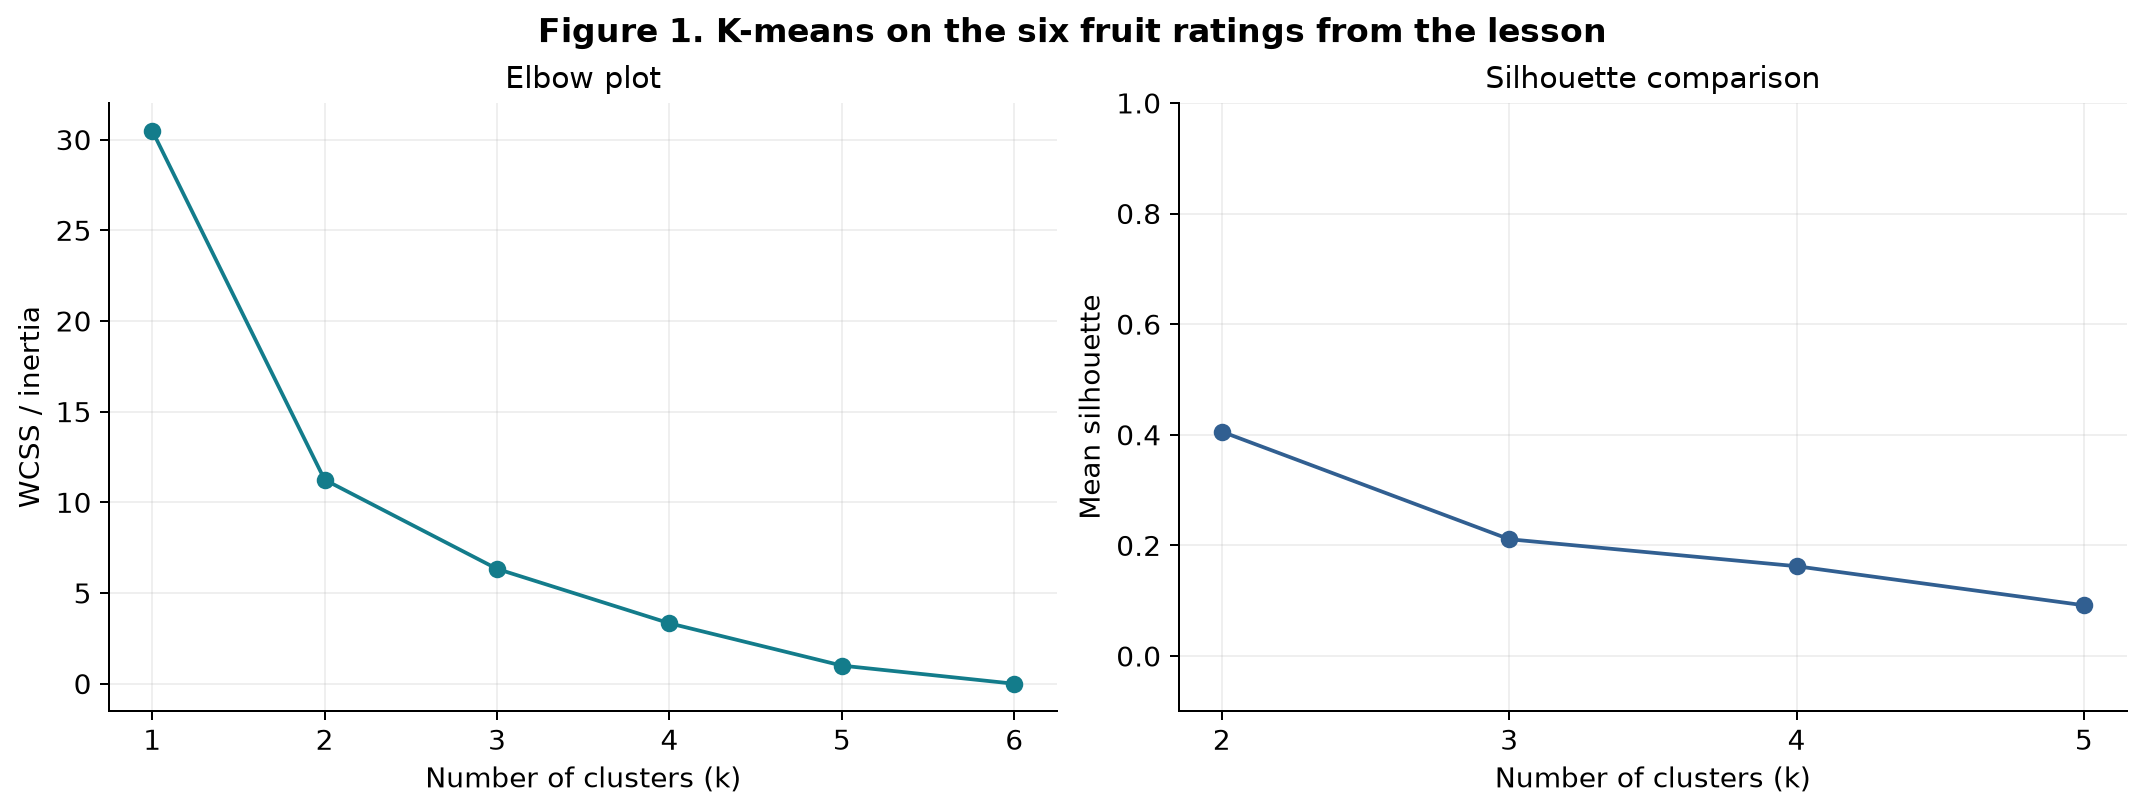

**What I take from this example:** Using one cluster per fruit makes inertia zero, but it does not give me a useful summary of the fruit. I need a way to balance a closer fit with a grouping I can actually explain. Silhouette is undefined when all six fruits are singletons.

In [3]:
fruit = pd.DataFrame({
    "Fruit": ["Apple", "Lemon", "Banana", "Grapefruit", "Mango", "Blueberry"],
    "Sweetness": [4, 1, 5, 3, 5, 3], "Sourness": [2, 5, 1, 4, 2, 3],
    "Bitterness": [1, 2, 1, 3, 1, 2], "Juiciness": [4, 5, 3, 5, 5, 3]
}).set_index("Fruit")
values = fruit.to_numpy(dtype=float)
initial_centers = fruit.loc[["Apple", "Grapefruit", "Lemon"]].to_numpy(dtype=float)
initial_labels = ((values[:, None, :] - initial_centers[None, :, :])**2).sum(axis=2).argmin(axis=1)
updated_centers = np.vstack([values[initial_labels == c].mean(axis=0) for c in range(3)])
updated_labels = ((values[:, None, :] - updated_centers[None, :, :])**2).sum(axis=2).argmin(axis=1)
example_wcss = float(((values - updated_centers[updated_labels])**2).sum())
show_table(fruit.assign(Initial_group=initial_labels+1, After_update=updated_labels+1).reset_index(), 2)
show_table(pd.DataFrame(updated_centers, columns=fruit.columns).assign(Group=[1, 2, 3])
           [["Group"] + fruit.columns.tolist()], 2)
print(f"WCSS after the lesson's center update: {example_wcss:.4f}")
print("Membership unchanged after the update:", np.array_equal(initial_labels, updated_labels))

fruit_rows = []
for k in range(1, 7):
    model = fit_kmeans(values, k)
    fruit_rows.append({"k": k, "Inertia": model.inertia_,
                      "Silhouette": safe_silhouette(values, model.labels_)})
fruit_scores = pd.DataFrame(fruit_rows)
show_table(fruit_scores, 4)
fruit_scores.to_csv(OUTPUT_DIR / "lesson_fruit_scores.csv", index=False)

points = np.array([[1., 1.], [1., -1.], [-2., 0.]])
distance_check = []
for name, center in [("Mean (0,0)", points.mean(axis=0)), ("Coordinate median (1,0)", np.median(points, axis=0))]:
    difference = points - center
    distance_check.append({"Center": name, "Sum of squared Euclidean distances": (difference**2).sum(),
                           "Sum of Manhattan distances": np.abs(difference).sum()})
show_table(pd.DataFrame(distance_check), 0)

fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.4), layout="constrained")
axes[0].plot(fruit_scores.k, fruit_scores.Inertia, "o-", color=TEAL)
axes[0].set(title="Elbow plot", xlabel="Number of clusters (k)", ylabel="WCSS / inertia", xticks=range(1, 7))
valid_fruit = fruit_scores.dropna(subset=["Silhouette"])
axes[1].plot(valid_fruit.k, valid_fruit.Silhouette, "o-", color=BLUE)
axes[1].set(title="Silhouette comparison", xlabel="Number of clusters (k)",
            ylabel="Mean silhouette", xticks=range(2, 6), ylim=(-.1, 1))
fig.suptitle("Figure 1. K-means on the six fruit ratings from the lesson", fontweight="bold")
finish(fig, "figure_1_lesson_example")
display(Markdown("**What I take from this example:** Using one cluster per fruit makes inertia zero, "
    "but it does not give me a useful summary of the fruit. I need a way to balance a closer fit "
    "with a grouping I can actually explain. Silhouette is undefined when all six fruits are singletons."))

## 3. Prepare the loan data
I use accepted loans with Fully Paid or Charged Off outcomes so I can describe repayment after the clusters are formed. That choice limits the analysis to resolved, accepted loans. It does not represent all applicants or loans still in progress.

The local reader retains a reproducible sample of 50,000 eligible loans. I take a random 10,000-loan subset for this exercise, without stratifying on the outcome. I fit on 8,000 loans and reserve 2,000 to check the grouping. The other sampled loans are unused. The code can reuse a compatible local sample or read the existing accepted-loans file; it never downloads the data.

I use six numeric features: loan amount, annual income, DTI, origination FICO, revolving utilization, and revolving balance. These give me a manageable set of financial characteristics to compare. I leave categorical features out of this exercise because one-hot encoding would introduce extra choices about how to weight category differences. Payments, recoveries, later credit scores, loan grades, interest rates, and the outcome label do not enter the clustering.

Negative amounts or ratios, nonpositive loan amounts, and FICO values outside 300-850 are marked missing using rules fixed in advance. Utilization above 100% is retained because it can occur. Missing numeric values are filled with fitting-set medians. I check repeated loan or borrower IDs before splitting; if borrower IDs are missing, independence remains a limitation.

In [4]:
def check_sample(sample, info):
    expected = {"cohort": "outcome", "seed": SEED, "sample_size": SAMPLE_SIZE,
                "chunk_size": CHUNK_SIZE, "algorithm": "priority-v1",
                "rows_scanned": EXPECTED_SOURCE_ROWS, "sample_rows": SAMPLE_SIZE}
    wrong = {key: (info.get(key), value) for key, value in expected.items()
             if info.get(key) != value}
    if wrong:
        raise ValueError(f"This cache does not match the configured sampling settings: {wrong}")
    missing = sorted(set(FEATURES + ["loan_status", "source_row"]) - set(sample.columns))
    if missing:
        raise ValueError(f"Sample columns missing: {missing}")
    if len(sample) != SAMPLE_SIZE:
        raise ValueError(f"Expected {SAMPLE_SIZE:,} sampled loans; found {len(sample):,}.")
    sample = sample.copy()
    sample["source_row"] = pd.to_numeric(sample["source_row"], errors="raise").astype("int64")
    if (sample.source_row.duplicated().any() or sample.source_row.lt(0).any()
            or sample.source_row.ge(EXPECTED_SOURCE_ROWS).any()):
        raise ValueError("Invalid or repeated source-row numbers in the sample.")
    sample["loan_status"] = sample.loan_status.astype("string").str.strip()
    if not sample.loan_status.isin(["Fully Paid", "Charged Off"]).all():
        raise ValueError("The sample must contain only Fully Paid and Charged Off loans.")
    return sample.reset_index(drop=True)

def read_sample_cache(path):
    path = Path(path).expanduser()
    if not str(path).endswith(".csv.gz"):
        raise ValueError("SAMPLE_PATH must name an existing outcome_*.csv.gz sample.")
    info_path = Path(str(path)[:-7] + ".json")
    if not path.is_file() or not info_path.is_file():
        raise FileNotFoundError(f"The sample and its matching JSON file are required: {path}")
    info = json.loads(info_path.read_text())
    sample = check_sample(pd.read_csv(path, dtype="string"), info)
    print("Using existing sample:", path)
    return sample, info, str(path.resolve())

def accepted_file(folder):
    folder = Path(folder).expanduser()
    if folder.is_file():
        return folder
    if not folder.is_dir():
        return None
    # Prefer the compressed copy when both representations are already present.
    for name in ["accepted_2007_to_2018Q4.csv.gz", "accepted_2007_to_2018Q4.csv"]:
        matches = sorted(p for p in folder.rglob(name) if p.is_file())
        if matches:
            return matches[0]
    return None

def locate_source(configured):
    configured = configured or os.environ.get("LENDING_CLUB_CSV")
    if configured:
        if str(configured).startswith(("http://", "https://")):
            raise ValueError("DATA_PATH must be a local file. The Kaggle URL is a citation.")
        found = accepted_file(configured)
        if found:
            return found
        raise FileNotFoundError(f"No accepted-loans file at DATA_PATH: {configured}")
    roots = [
        Path.home()/".cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3",
        Path("/home/codespace/.cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3"),
        Path.cwd()/"data", Path.cwd(), Path("/kaggle/input"), Path("/content")
    ]
    for root in roots:
        found = accepted_file(root)
        if found:
            return found
    raise FileNotFoundError(
        "No existing accepted-loans file or compatible local sample cache was found. "
        "Set DATA_PATH to your local accepted_2007_to_2018Q4.csv.gz (or .csv), "
        "or set SAMPLE_PATH to your existing outcome_*.csv.gz with its JSON file. "
        "This notebook does not download data."
    )

def sample_source(path):
    header = pd.read_csv(path, nrows=0)
    missing = sorted(set(FEATURES + ["loan_status"]) - set(header.columns))
    if missing:
        raise ValueError(f"Required accepted-loans columns missing: {missing}")
    requested = list(dict.fromkeys(FEATURES + ["int_rate", "loan_status", "id", "member_id", "issue_d"]))
    requested = [col for col in requested if col in header.columns]
    fingerprint = {"resolved_path": str(path.resolve()), "bytes": path.stat().st_size,
        "mtime_ns": path.stat().st_mtime_ns, "cohort": "outcome", "seed": SEED,
        "sample_size": SAMPLE_SIZE, "chunk_size": CHUNK_SIZE, "algorithm": "priority-v1"}
    rng = np.random.default_rng(SEED)
    sample, scanned, eligible = None, 0, 0
    status_counts = pd.Series(dtype="int64")
    for batch, chunk in enumerate(pd.read_csv(path, usecols=requested, dtype="string",
                    chunksize=CHUNK_SIZE, low_memory=False), 1):
        chunk["source_row"] = np.arange(scanned, scanned + len(chunk))
        scanned += len(chunk)
        chunk["loan_status"] = chunk.loan_status.str.strip()
        status_counts = status_counts.add(
            chunk.loan_status.fillna("Missing").value_counts(), fill_value=0)
        chunk = chunk.loc[chunk.loan_status.isin(["Fully Paid", "Charged Off"])].copy()
        eligible += len(chunk)
        if len(chunk):
            chunk["_priority"] = rng.random(len(chunk))
            sample = chunk if sample is None else pd.concat([sample, chunk], ignore_index=True)
            sample = sample.nsmallest(SAMPLE_SIZE, "_priority")
        if batch % 20 == 0:
            print(f"Scanned {scanned:,} rows | eligible loans: {eligible:,}", flush=True)
    if scanned != EXPECTED_SOURCE_ROWS:
        raise ValueError(f"Read {scanned:,} rows; the accepted-loans version-3 file has "
                         f"{EXPECTED_SOURCE_ROWS:,}. Check that the source file is complete.")
    if sample is None:
        raise ValueError("No eligible loans were found.")
    sample = sample.drop(columns="_priority").reset_index(drop=True)
    info = {**fingerprint, "rows_scanned": scanned, "eligible_rows": eligible,
            "sample_rows": len(sample)}
    sample = check_sample(sample, info)
    key = hashlib.sha256(json.dumps(fingerprint, sort_keys=True).encode()).hexdigest()[:16]
    cache_file = CACHE_DIR / f"outcome_{key}.csv.gz"
    sample.to_csv(cache_file, index=False, compression="gzip")
    (CACHE_DIR / f"outcome_{key}.json").write_text(json.dumps(info, indent=2))
    status_counts.astype(int).to_csv(OUTPUT_DIR / "source_status_counts.csv")
    return sample, info, str(path.resolve())

def load_loans():
    if SAMPLE_PATH is not None and DATA_PATH is not None:
        raise ValueError("Set only SAMPLE_PATH or DATA_PATH, so the intended source is clear.")
    if SAMPLE_PATH is not None:
        return read_sample_cache(SAMPLE_PATH)
    if DATA_PATH is None and not os.environ.get("LENDING_CLUB_CSV"):
        for candidate in sorted(CACHE_DIR.glob("outcome_*.csv.gz")):
            try:
                return read_sample_cache(candidate)
            except (ValueError, FileNotFoundError, KeyError) as error:
                print(f"Skipping incompatible cache {candidate.name}: {error}")
    source = locate_source(DATA_PATH)
    print("Using existing dataset:", source)
    # Reuse a saved sample from this exact source if available.
    for candidate in sorted(CACHE_DIR.glob("outcome_*.csv.gz")):
        info_path = Path(str(candidate)[:-7] + ".json")
        if info_path.is_file():
            info = json.loads(info_path.read_text())
            if (info.get("resolved_path") == str(source.resolve())
                and info.get("bytes") == source.stat().st_size
                and info.get("mtime_ns") == source.stat().st_mtime_ns):
                return read_sample_cache(candidate)
    return sample_source(source)

In [5]:
loans, source_info, source_used = load_loans()
study = loans.sample(n=ANALYSIS_SIZE, random_state=SEED).copy()
for key in ["id", "member_id"]:
    if key in study:
        ids = study[key].astype("string").str.strip().replace("", pd.NA).dropna()
        if ids.duplicated().any():
            raise ValueError(f"Repeated {key}: resolve duplicate loans or use borrower-group splits first.")
if "member_id" not in study or study.member_id.astype("string").str.strip().replace("", pd.NA).isna().all():
    print("No usable borrower ID: repeated borrowers cannot be fully checked.")

X = study[CLUSTER_FEATURES].apply(clean_number)
invalid = pd.DataFrame(False, index=X.index, columns=X.columns)
for col in ["loan_amnt", "annual_inc", "dti", "revol_util", "revol_bal"]:
    invalid[col] = X[col].lt(0)
invalid["loan_amnt"] = X.loan_amnt.le(0)
invalid["fico_range_low"] = X.fico_range_low.notna() & ~X.fico_range_low.between(300, 850)
X = X.mask(invalid)
X_fit, X_check = train_test_split(X, test_size=.20, random_state=SEED)
assert set(X_fit.index).isdisjoint(X_check.index)
assert "loan_status" not in X.columns
if X_fit.isna().all().any():
    raise ValueError("At least one clustering feature is entirely missing in the fitting set.")

split_manifest = study[["source_row"]].copy()
split_manifest["split"] = "reserved check"
split_manifest.loc[X_fit.index, "split"] = "fit and choose k"
split_manifest.to_csv(OUTPUT_DIR / "split_manifest.csv", index=False)
show_table(pd.DataFrame({"Stage": ["Resolved-loan sample", "Clustering subset", "Fit and choose k", "Reserved check"],
                        "Loans": [len(loans), len(study), len(X_fit), len(X_check)]}), 0)
run_info = {"data_url": DATASET_URL, "source_used": source_used, "source_metadata": source_info,
    "seed": SEED, "analysis_rows": len(study), "features": CLUSTER_FEATURES,
    "fit_source_rows_sha256": hashlib.sha256(study.loc[X_fit.index, "source_row"].to_numpy(dtype="int64").tobytes()).hexdigest(),
    "python": sys.version.split()[0], "sklearn": sklearn.__version__, "pandas": pd.__version__}
(OUTPUT_DIR / "run_provenance.json").write_text(json.dumps(run_info, indent=2))
print("Loan outcomes are set aside until the grouping and checks are fixed.")

Using existing sample: capstone_cache/outcome_6052281cfec00759.csv.gz
No usable borrower ID: repeated borrowers cannot be fully checked.


Stage,Loans
Resolved-loan sample,50000
Clustering subset,10000
Fit and choose k,8000
Reserved check,2000


Loan outcomes are set aside until the grouping and checks are fixed.


## 4. Check the ranges and scale the features
Loan amount, income, and revolving balance are measured in dollars, while the other features have very different ranges. I expect those differences to affect the groups if I use the original units. Large values also matter because K-means squares the distance to the center.

For the main analysis, I use log(1 + value) on the three dollar features, then standardize all six features. The log transformation reduces the influence of very large dollar values. Standardization uses the fitting-set mean and standard deviation. These steps change the geometry; they do not remove every outlier or make every feature equally useful. I keep the preprocessing fixed before choosing k.

I also prepare an original-units version and a standardization only version for a later sensitivity comparison. Figure 2 shows which numeric features dominate squared distance before and after the main transformation. The range and outlier tables help me check what is still unusual. They use fitting data only.

Feature,min,median,max,Missing (%),Invalid values marked missing
loan_amnt,"1,000.00","12,000.00","40,000.00",0.00,0
annual_inc,0.00,"65,000.00","1,320,000.00",0.00,0
dti,0.00,17.39,178.31,0.03,0
fico_range_low,660.00,690.00,840.00,0.00,0
revol_util,0.00,52.00,154.90,0.04,0
revol_bal,0.00,"11,088.50","1,696,796.00",0.00,0


Feature,Largest |z|: standardization only,Largest |z|: log dollars + standardization,Main transform: share |z| > 3
loan_amnt,2.940,3.542,0.008
annual_inc,20.653,19.151,0.007
dti,17.717,17.717,0.003
fico_range_low,4.466,4.466,0.016
revol_util,4.234,4.234,0.000
revol_bal,50.471,7.484,0.011


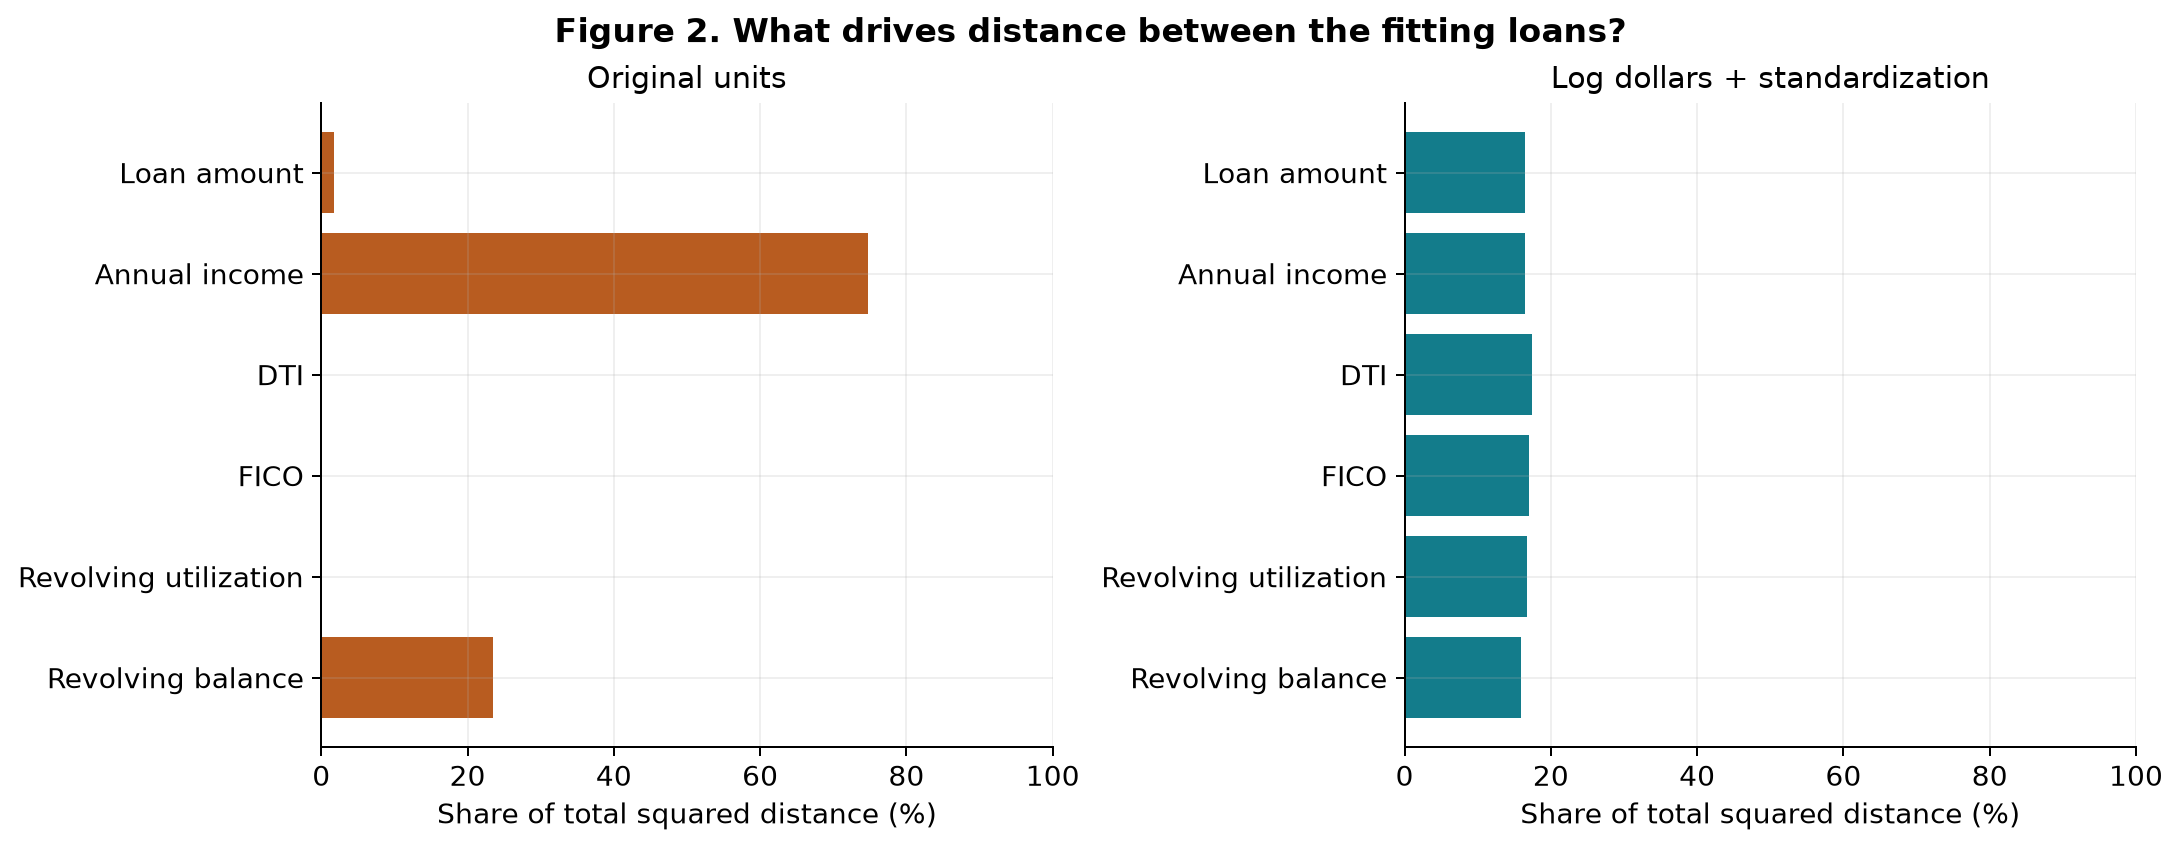

**What I see:** `annual_inc` accounts for 74.8% of squared distance across these random loan pairs in the original units. The second panel shows how the main transformation changes that balance. This is a distance check, not feature importance.

In [6]:
def log_money(values):
    result = np.asarray(values, dtype=float).copy()
    result[:, MONEY_POSITIONS] = np.log1p(result[:, MONEY_POSITIONS])
    return result

def make_prepare(method="Log dollars + standardization"):
    steps = [("impute", SimpleImputer(strategy="median", keep_empty_features=True))]
    if method == "Log dollars + standardization":
        steps.append(("log_money", FunctionTransformer(log_money, validate=False)))
    if method in ["Standardization only", "Log dollars + standardization"]:
        steps.append(("scale", StandardScaler()))
    elif method != "Original units":
        raise ValueError(f"Unknown method: {method}")
    return Pipeline(steps)

MAIN_METHOD = "Log dollars + standardization"
prepare = make_prepare(MAIN_METHOD)
Z_fit = prepare.fit_transform(X_fit)
raw_fit = make_prepare("Original units").fit_transform(X_fit)
standard_fit = make_prepare("Standardization only").fit_transform(X_fit)
range_table = X_fit.agg(["min", "median", "max"]).T.rename_axis("Feature").reset_index()
range_table["Missing (%)"] = X_fit.isna().mean().mul(100).to_numpy()
range_table["Invalid values marked missing"] = invalid.loc[X_fit.index].sum().to_numpy()
show_table(range_table, 2)
range_table.to_csv(OUTPUT_DIR / "fitting_ranges_missingness.csv", index=False)
outlier_table = pd.DataFrame({"Feature": CLUSTER_FEATURES,
    "Largest |z|: standardization only": np.abs(standard_fit).max(axis=0),
    "Largest |z|: log dollars + standardization": np.abs(Z_fit).max(axis=0),
    "Main transform: share |z| > 3": (np.abs(Z_fit) > 3).mean(axis=0)})
show_table(outlier_table)
outlier_table.to_csv(OUTPUT_DIR / "outlier_check.csv", index=False)

pair_rng = np.random.default_rng(SEED)
left = pair_rng.integers(0, len(Z_fit), 5_000)
right = (left + pair_rng.integers(1, len(Z_fit), 5_000)) % len(Z_fit)
distance_shares = {}
for method, values in [("Original units", raw_fit), (MAIN_METHOD, Z_fit)]:
    contributions = ((values[left] - values[right])**2).sum(axis=0)
    distance_shares[method] = contributions / contributions.sum()
distance_table = pd.DataFrame({"Feature": CLUSTER_FEATURES, **distance_shares})
distance_table.to_csv(OUTPUT_DIR / "distance_contributions.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained")
for ax, method, color in [(axes[0], "Original units", ORANGE), (axes[1], MAIN_METHOD, TEAL)]:
    ax.barh(SHORT_NAMES[::-1], distance_shares[method][::-1]*100, color=color)
    ax.set(title=method, xlabel="Share of total squared distance (%)", xlim=(0, 100))
fig.suptitle("Figure 2. What drives distance between the fitting loans?", fontweight="bold")
finish(fig, "figure_2_scaling_distance")
largest = distance_table.loc[distance_table["Original units"].idxmax()]
display(Markdown(f"**What I see:** `{largest.Feature}` accounts for {largest['Original units']:.1%} "
    "of squared distance across these random loan pairs in the original units. The second panel "
    "shows how the main transformation changes that balance. This is a distance check, not feature importance."))

## 5. Compare the elbow and silhouette results
I fit k = 1 through 8 for the elbow plot. For k = 2 through 8, I also calculate silhouette using the same random subset of up to 1,000 fitting loans. Using a fixed subset makes the comparison less expensive and keeps changes in the evaluated rows from explaining differences between k values. The score is an estimate for that subset, not the exact mean over all fitting loans.

I use k-means++ initialization with 20 starts and keep the run with the lowest inertia for each k. Multiple starts reduce the chance of keeping a poor local solution. The 500-iteration limit and tolerance control when fitting stops; they do not by themselves prevent overfitting.

My selection rule is the highest fitting-subset silhouette, with the smaller k winning an exact tie. I use the elbow plot and cluster sizes to judge whether that choice makes sense. The code marks a possible bend using the largest gap below the line joining the normalized curve's endpoints. This is a visual aid, not proof of a true elbow. If the curve or scores are ambiguous, I will say so instead of forcing a strong conclusion.

The lowest possible WCSS cannot increase as k grows, but separate fitted solutions can get stuck in local minima. The code reports any increase so I can check it. I do not choose k using repayment outcomes or the reserved loans.

k,Inertia,Mean squared distance,Silhouette,Clusters in silhouette subset,Smallest fitting cluster,Smallest cluster share,Iterations,Inertia reduction (%)
1,"48,000.0000",6.0000,NaN,1,8000,1.0000,2,NaN
2,"38,586.6777",4.8233,0.2189,2,3037,0.3796,9,19.6111
3,"32,826.9820",4.1034,0.1877,3,1550,0.1938,12,14.9266
4,"29,622.5351",3.7028,0.1668,4,1234,0.1542,15,9.7616
5,"27,227.9806",3.4035,0.1793,5,97,0.0121,32,8.0836
6,"25,294.0281",3.1618,0.1593,6,95,0.0119,44,7.1028
7,"23,659.7800",2.9575,0.1550,7,75,0.0094,55,6.4610
8,"22,523.1275",2.8154,0.1543,8,72,0.0090,61,4.8042


Selected k = 2; fitting-subset silhouette = 0.2189
Possible elbow from the curve heuristic: 3


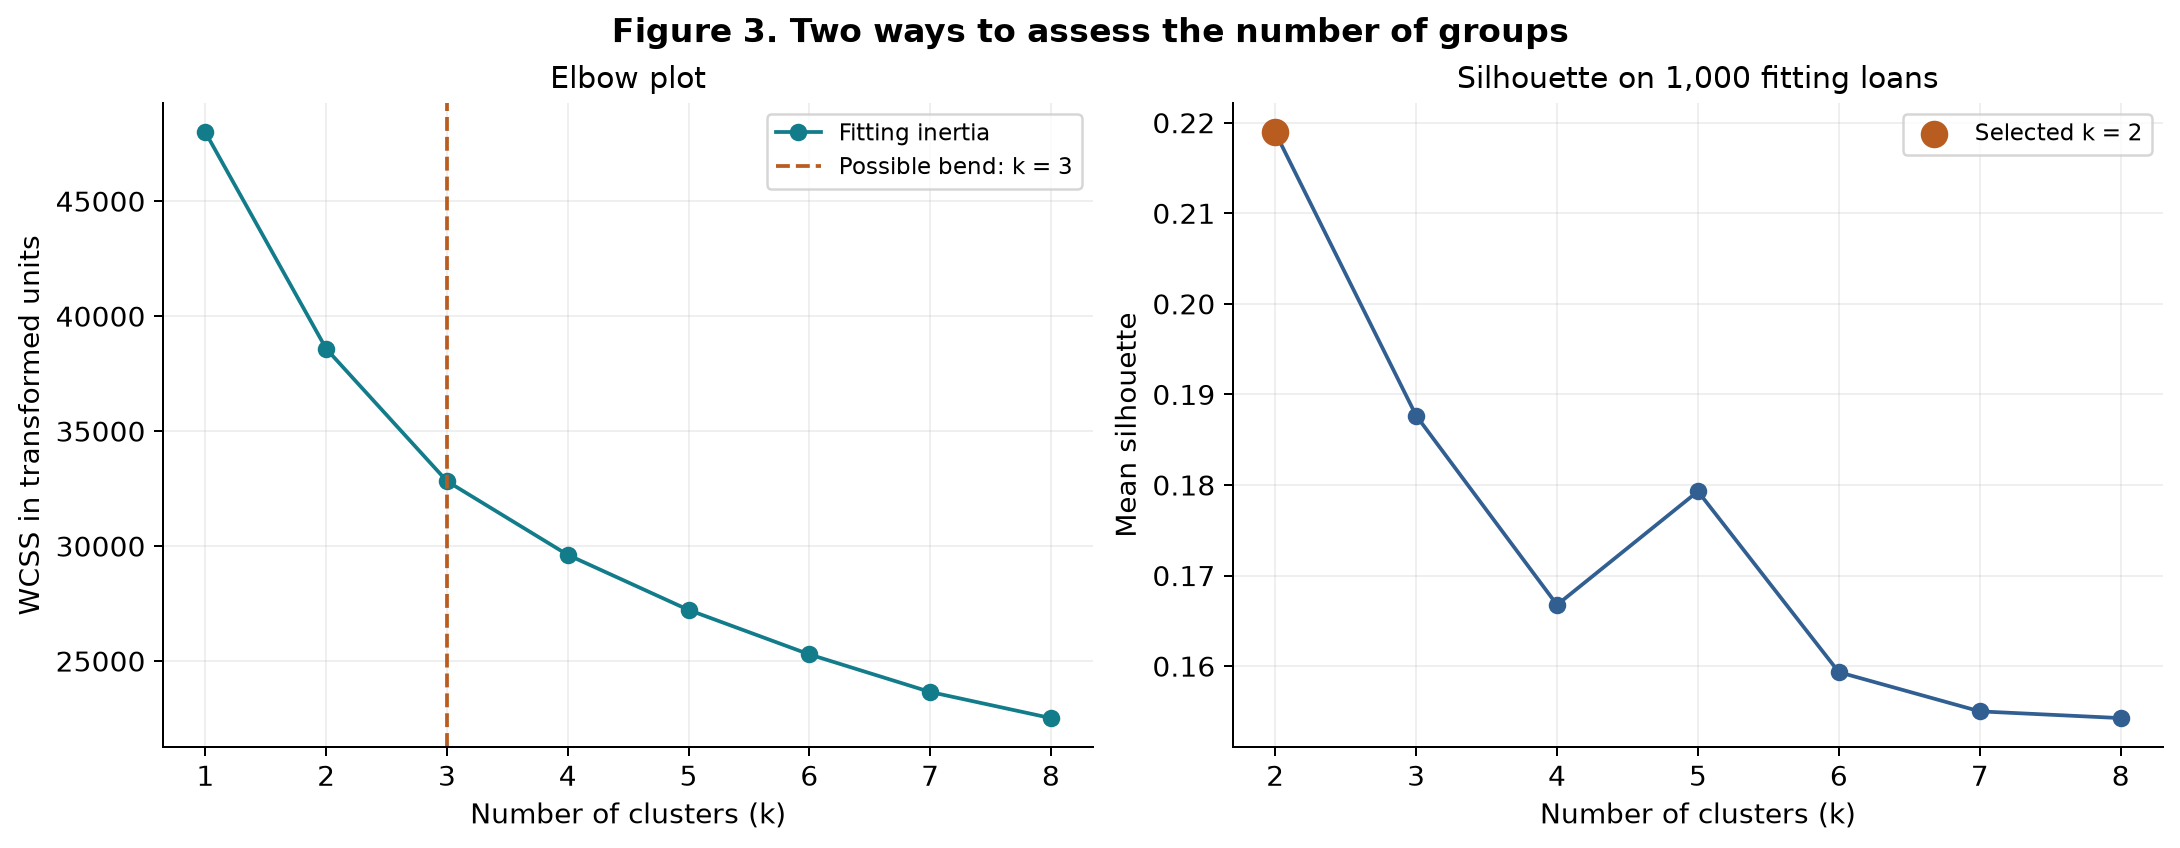

273

In [7]:
eval_rng = np.random.default_rng(SEED)
fit_eval_positions = np.sort(eval_rng.choice(len(Z_fit), min(SILHOUETTE_SAMPLE, len(Z_fit)), replace=False))
fit_models, rows = {}, []
for k in K_VALUES:
    model = fit_kmeans(Z_fit, k)
    fit_models[k] = model
    group_counts = np.bincount(model.labels_, minlength=k)
    labels_eval = model.labels_[fit_eval_positions]
    rows.append({"k": k, "Inertia": float(model.inertia_),
        "Mean squared distance": float(model.inertia_/len(Z_fit)),
        "Silhouette": safe_silhouette(Z_fit[fit_eval_positions], labels_eval),
        "Clusters in silhouette subset": int(len(np.unique(labels_eval))),
        "Smallest fitting cluster": int(group_counts.min()),
        "Smallest cluster share": float(group_counts.min()/len(Z_fit)),
        "Iterations": int(model.n_iter_)})
k_results = pd.DataFrame(rows)
k_results["Inertia reduction (%)"] = -k_results.Inertia.pct_change()*100
show_table(k_results, 4)
k_results.to_csv(OUTPUT_DIR / "k_selection.csv", index=False)
eligible_scores = k_results.loc[k_results.k.ge(2)].dropna(subset=["Silhouette"])
if eligible_scores.empty:
    raise ValueError("No valid silhouette score. Check whether the data or sample has enough distinct groups.")
selected_row = eligible_scores.sort_values(["Silhouette", "k"], ascending=[False, True]).iloc[0]
selected_k = int(selected_row.k)
selected_model = fit_models[selected_k]
fit_labels = selected_model.labels_

curve_x = (k_results.k - k_results.k.min()) / (k_results.k.max() - k_results.k.min())
curve_y = (k_results.Inertia - k_results.Inertia.min()) / (k_results.Inertia.max() - k_results.Inertia.min())
bend_gap = 1 - curve_x.to_numpy() - curve_y.to_numpy()
bend_position = int(np.argmax(bend_gap))
elbow_hint = int(k_results.iloc[bend_position].k) if bend_gap[bend_position] > 1e-8 and 0 < bend_position < len(k_results)-1 else None
if k_results.Inertia.diff().dropna().gt(1e-7).any():
    print("Inertia increased for at least one fitted k. Check optimization before interpreting the elbow.")
print(f"Selected k = {selected_k}; fitting-subset silhouette = {selected_row.Silhouette:.4f}")
print("Possible elbow from the curve heuristic:", elbow_hint)
if selected_row["Smallest cluster share"] < .01:
    print("Caution: the selected model contains a cluster with under 1% of fitting loans. Inspect outliers and profiles.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained")
axes[0].plot(k_results.k, k_results.Inertia, "o-", color=TEAL, label="Fitting inertia")
if elbow_hint is not None:
    axes[0].axvline(elbow_hint, color=ORANGE, ls="--", label=f"Possible bend: k = {elbow_hint}")
axes[0].set(title="Elbow plot", xlabel="Number of clusters (k)", ylabel="WCSS in transformed units", xticks=K_VALUES)
axes[0].legend(fontsize=9)
axes[1].plot(eligible_scores.k, eligible_scores.Silhouette, "o-", color=BLUE)
axes[1].scatter([selected_k], [selected_row.Silhouette], s=100, color=ORANGE, zorder=3, label=f"Selected k = {selected_k}")
axes[1].set(title=f"Silhouette on {len(fit_eval_positions):,} fitting loans", xlabel="Number of clusters (k)",
            ylabel="Mean silhouette", xticks=K_VALUES[1:])
axes[1].legend(fontsize=9)
fig.suptitle("Figure 3. Two ways to assess the number of groups", fontweight="bold")
finish(fig, "figure_3_elbow_silhouette")
frozen = {"features": CLUSTER_FEATURES, "method": MAIN_METHOD, "k": selected_k,
          "seed": SEED, "n_init": N_INIT, "max_iter": MAX_ITER, "selection": "fitting-subset silhouette"}
(OUTPUT_DIR / "frozen_cluster_settings.json").write_text(json.dumps(frozen, indent=2))

## 6. Look at the groups before checking outcomes
An average silhouette can hide differences between groups. Figure 4 shows the individual silhouette values for the sampled fitting loans. Wide sections below zero would make me question whether those loans fit their assigned group.

The second panel uses PCA to show the six-feature clustering in two dimensions. K-means is fitted in the full six-dimensional transformed space. PCA is only used for the picture, and I report how much variation the two displayed components retain. Points that look close in this plot may be farther apart in the full space.

Figure 5 shows the fitted centers in transformed standard-deviation units. Dollar features were logged first. I also report medians in the original units, which are easier to explain. The original-unit medians are group summaries; they are not inverse-transformed K-means centroids. Cluster numbers are arbitrary and do not represent a risk ranking.

Cluster,Loans,loan_amnt,annual_inc,dti,fico_range_low,revol_util,revol_bal
1,4963,"16,000.00","74,000.00",19.00,685.00,63.50,"16,086.00"
2,3037,"8,000.00","51,000.00",14.56,705.00,30.10,"5,521.00"


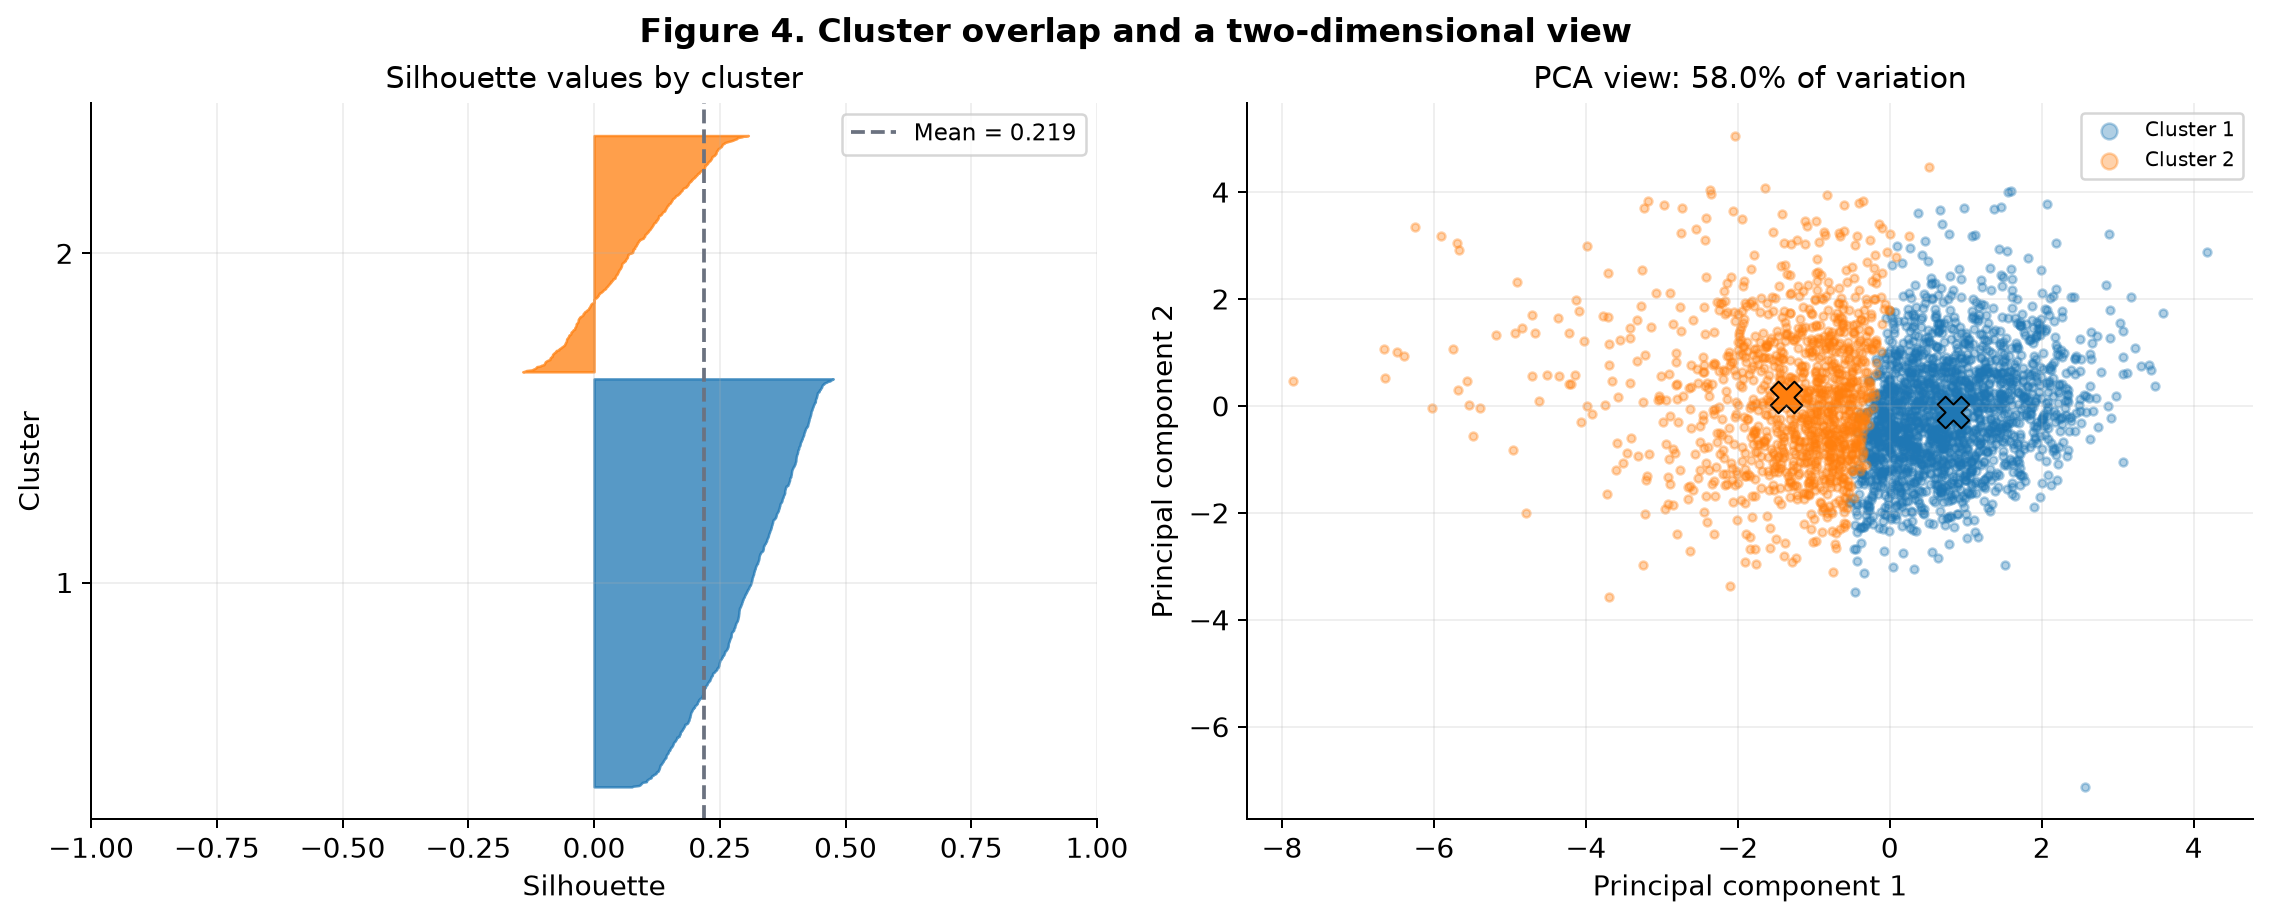

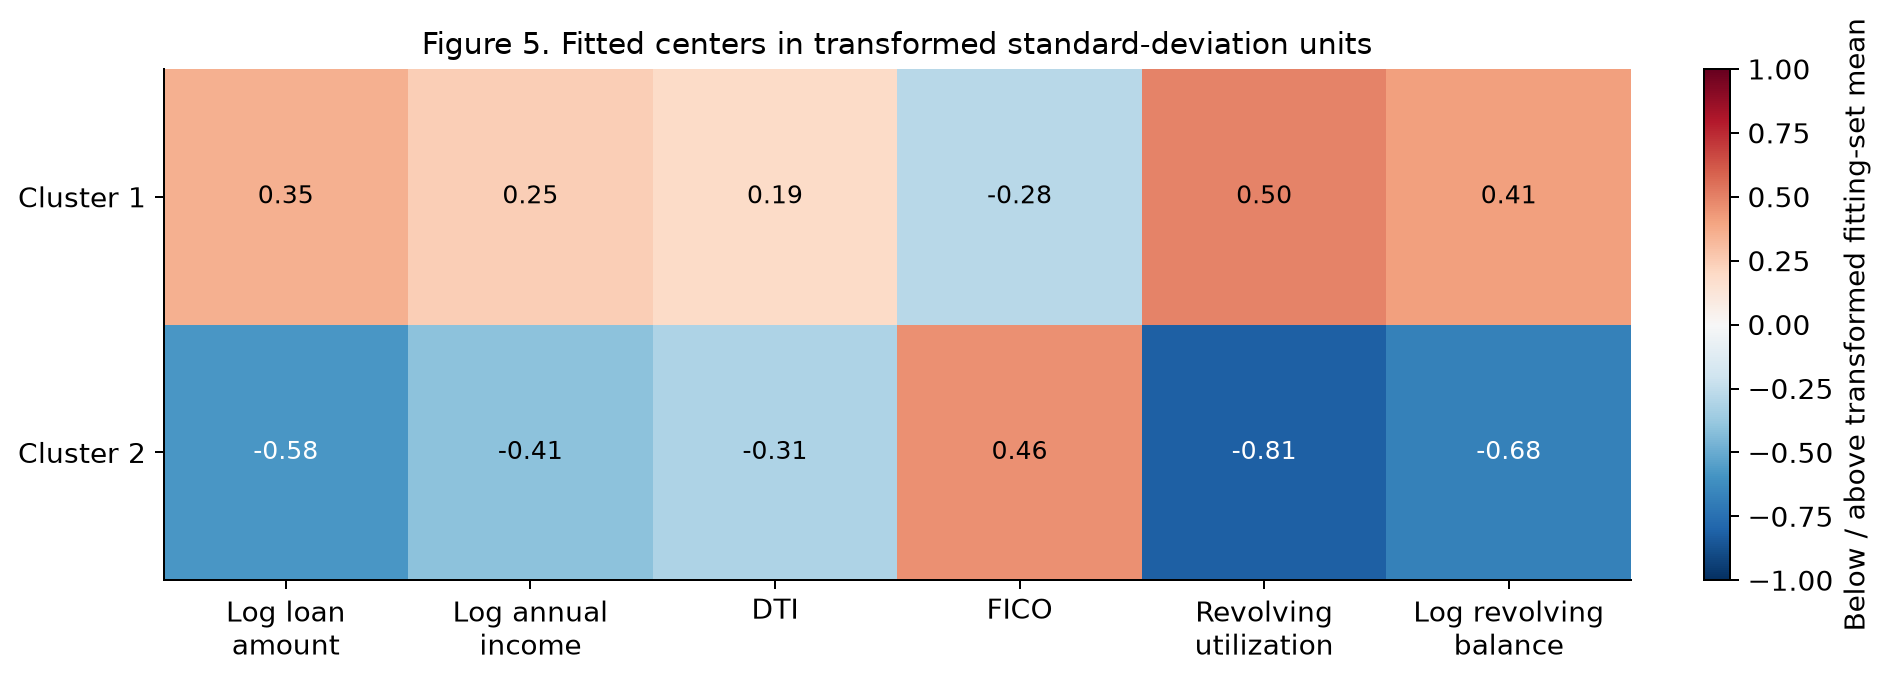

In [8]:
fit_eval_labels = fit_labels[fit_eval_positions]
fit_sil_values = silhouette_samples(Z_fit[fit_eval_positions], fit_eval_labels, metric="euclidean")
fit_negative_share = float((fit_sil_values < 0).mean())
feature_profiles = X_fit.assign(Cluster=fit_labels+1).groupby("Cluster").median()
feature_profiles.insert(0, "Loans", pd.Series(fit_labels+1).value_counts().reindex(feature_profiles.index).to_numpy())
show_table(feature_profiles.reset_index(), 2)
feature_profiles.to_csv(OUTPUT_DIR / "fitting_cluster_profiles.csv")
center_table = pd.DataFrame(selected_model.cluster_centers_, columns=CLUSTER_FEATURES,
                            index=pd.Index(range(1, selected_k+1), name="Cluster"))
center_table.to_csv(OUTPUT_DIR / "centers_transformed_units.csv")

pca = PCA(n_components=2, svd_solver="full").fit(Z_fit)
plot_positions = np.sort(np.random.default_rng(SEED).choice(len(Z_fit), min(3000, len(Z_fit)), replace=False))
projected = pca.transform(Z_fit[plot_positions])
projected_centers = pca.transform(selected_model.cluster_centers_)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5), layout="constrained")
lower, tick_positions, tick_labels = 10, [], []
for group in range(selected_k):
    band = np.sort(fit_sil_values[fit_eval_labels == group])
    if len(band):
        upper = lower + len(band)
        axes[0].fill_betweenx(np.arange(lower, upper), 0, band, color=COLORS[group], alpha=.75)
        tick_positions.append((lower + upper)/2); tick_labels.append(str(group+1))
        lower = upper + 10
    mask = fit_labels[plot_positions] == group
    axes[1].scatter(projected[mask, 0], projected[mask, 1], s=10, alpha=.35,
                    color=COLORS[group], label=f"Cluster {group+1}")
    axes[1].scatter(projected_centers[group, 0], projected_centers[group, 1], marker="X", s=160,
                    color=COLORS[group], edgecolor="black", linewidth=.8)
axes[0].axvline(fit_sil_values.mean(), color=GRAY, ls="--", label=f"Mean = {fit_sil_values.mean():.3f}")
axes[0].set(title="Silhouette values by cluster", xlabel="Silhouette", ylabel="Cluster",
            yticks=tick_positions, yticklabels=tick_labels, xlim=(-1, 1))
axes[0].legend(fontsize=9)
axes[1].set(title=f"PCA view: {pca.explained_variance_ratio_.sum():.1%} of variation", xlabel="Principal component 1",
            ylabel="Principal component 2")
axes[1].legend(fontsize=8, markerscale=2)
fig.suptitle("Figure 4. Cluster overlap and a two-dimensional view", fontweight="bold")
finish(fig, "figure_4_cluster_separation")

fig, ax = plt.subplots(figsize=(10.4, max(3.6, .55*selected_k+1.7)), layout="constrained")
limit = max(1., float(np.abs(selected_model.cluster_centers_).max()))
im = ax.imshow(selected_model.cluster_centers_, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
ax.set(xticks=range(6), xticklabels=["Log loan\namount", "Log annual\nincome", "DTI", "FICO",
                                   "Revolving\nutilization", "Log revolving\nbalance"],
       yticks=range(selected_k), yticklabels=[f"Cluster {i}" for i in range(1, selected_k+1)],
       title="Figure 5. Fitted centers in transformed standard-deviation units")
ax.grid(False)
for row in range(selected_k):
    for col in range(6):
        value = selected_model.cluster_centers_[row, col]
        ax.text(col, row, f"{value:.2f}", ha="center", va="center",
                color="white" if abs(value) > limit*.55 else "black", fontsize=10)
fig.colorbar(im, ax=ax, label="Below / above transformed fitting-set mean")
finish(fig, "figure_5_cluster_centers")

## 7. Check how scaling changes the grouping
Now that k is fixed, I fit the same number of clusters using original units and standardization without the log step. I compare the assignments with the main model using adjusted Rand index (ARI). An ARI of 1 means the partitions agree, even if the cluster numbers are different. A score around 0 means agreement is close to what would be expected by chance.

I also report silhouette and cluster sizes for each representation. Those silhouettes describe different distance spaces, so a higher value is not a fair claim that one representation predicts repayment better. Inertia is also tied to the units and should not be compared directly across these transformations. I keep the main model fixed and use this as a sensitivity check.

In [9]:
scaling_rows = []
for method in ["Original units", "Standardization only", MAIN_METHOD]:
    if method == MAIN_METHOD:
        values, model = Z_fit, selected_model
    else:
        values = make_prepare(method).fit_transform(X_fit)
        model = fit_kmeans(values, selected_k)
    counts = np.bincount(model.labels_, minlength=selected_k)
    scaling_rows.append({"Representation": method,
        "Silhouette in its own space": safe_silhouette(values[fit_eval_positions], model.labels_[fit_eval_positions]),
        "ARI with main grouping": adjusted_rand_score(fit_labels, model.labels_),
        "Smallest cluster": int(counts.min()), "Largest cluster": int(counts.max())})
scaling_results = pd.DataFrame(scaling_rows)
show_table(scaling_results, 4)
scaling_results.to_csv(OUTPUT_DIR / "scaling_sensitivity.csv", index=False)

Representation,Silhouette in its own space,ARI with main grouping,Smallest cluster,Largest cluster
Original units,0.7576,-0.0200,383,7617
Standardization only,0.2097,0.4232,2982,5018
Log dollars + standardization,0.2189,1.0000,3037,4963


## 8. Check new assignments and stability
I assign the 2,000 reserved loans to the already fitted centers. I do not refit the scaler or centers on these loans. I compare mean squared distance to the assigned center and estimate silhouette on up to 1,000 reserved loans. These are checks on the grouping, not classification accuracy.

I also check whether changing the random seed or using 80% of the fitting loans changes the assignments. For the smaller fitting samples, I refit preprocessing as well as K-means. I compare assignments on the same reserved loans with ARI. I keep k fixed during these checks.

Restricting k, using multiple starts, reserving observations, and checking stability help me avoid treating a very detailed or unstable partition as a strong result. They do not prove that the clusters are natural borrower types. I do not use the reserved results to revise the selected model.

In [10]:
Z_check = prepare.transform(X_check)
check_labels = selected_model.predict(Z_check)
check_eval_positions = np.sort(np.random.default_rng(SEED+1).choice(
    len(Z_check), min(SILHOUETTE_SAMPLE, len(Z_check)), replace=False))
check_silhouette = safe_silhouette(Z_check[check_eval_positions], check_labels[check_eval_positions])
validation_results = pd.DataFrame([
    {"Data": "Fitting", "Loans": len(Z_fit), "Silhouette rows": len(fit_eval_positions),
     "Mean squared distance": float(np.mean(np.sum((Z_fit-selected_model.cluster_centers_[fit_labels])**2, axis=1))),
     "Silhouette": float(fit_sil_values.mean()), "Clusters represented": len(np.unique(fit_labels))},
    {"Data": "Reserved check", "Loans": len(Z_check), "Silhouette rows": len(check_eval_positions),
     "Mean squared distance": float(np.mean(np.sum((Z_check-selected_model.cluster_centers_[check_labels])**2, axis=1))),
     "Silhouette": check_silhouette, "Clusters represented": len(np.unique(check_labels))}
])
show_table(validation_results, 4)
validation_results.to_csv(OUTPUT_DIR / "reserved_grouping_check.csv", index=False)

stability_rows = []
for seed in [7, 21, 99]:
    alternate = fit_kmeans(Z_fit, selected_k, seed=seed)
    seed_labels = alternate.predict(Z_check)
    stability_rows.append({"Check": "Different seed; same fitting loans", "Seed": seed,
        "Fitting loans": len(X_fit), "Reserved ARI": adjusted_rand_score(check_labels, seed_labels)})
    positions = np.random.default_rng(seed).choice(len(X_fit), int(.8*len(X_fit)), replace=False)
    subset_prepare = make_prepare(MAIN_METHOD)
    subset_values = subset_prepare.fit_transform(X_fit.iloc[positions])
    subset_model = fit_kmeans(subset_values, selected_k, seed=seed)
    subset_labels = subset_model.predict(subset_prepare.transform(X_check))
    stability_rows.append({"Check": "80% fitting sample; preprocessing refitted", "Seed": seed,
        "Fitting loans": len(positions), "Reserved ARI": adjusted_rand_score(check_labels, subset_labels)})
stability_results = pd.DataFrame(stability_rows)
show_table(stability_results, 4)
stability_results.to_csv(OUTPUT_DIR / "cluster_stability.csv", index=False)

Data,Loans,Silhouette rows,Mean squared distance,Silhouette,Clusters represented
Fitting,8000,1000,4.8233,0.2189,2
Reserved check,2000,1000,5.8483,0.2286,2


Check,Seed,Fitting loans,Reserved ARI
Different seed; same fitting loans,7,8000,0.9880
80% fitting sample; preprocessing refitted,7,6400,0.8925
Different seed; same fitting loans,21,8000,0.9900
80% fitting sample; preprocessing refitted,21,6400,0.9485
Different seed; same fitting loans,99,8000,0.9348
80% fitting sample; preprocessing refitted,99,6400,0.9820


## 9. Bring repayment outcomes back into the analysis
Only now do I compare repayment outcomes across the groups. I use the reserved loans and show both the charge-off share and the number of loans behind it. Small groups can produce unstable percentages, so I include approximate 95% Wilson intervals. These assume independent observations and do not include uncertainty from choosing the features or k.

I also show the reserved groups' median financial characteristics. These comparisons can suggest questions for further analysis, but a higher charge-off share does not make a cluster a validated risk class. I have not measured classification performance or shown that the cluster characteristics cause charge-offs.

Cluster,Loans,Charged_off,Charge-off share,Lower 95%,Upper 95%
1,1235,270,0.2186,0.1965,0.2425
2,765,131,0.1712,0.1462,0.1996


Cluster,loan_amnt,annual_inc,dti,fico_range_low,revol_util,revol_bal
1,"16,000.00","75,000.00",19.76,680.00,64.80,"16,489.00"
2,"8,000.00","50,000.00",15.96,705.00,29.40,"5,653.00"


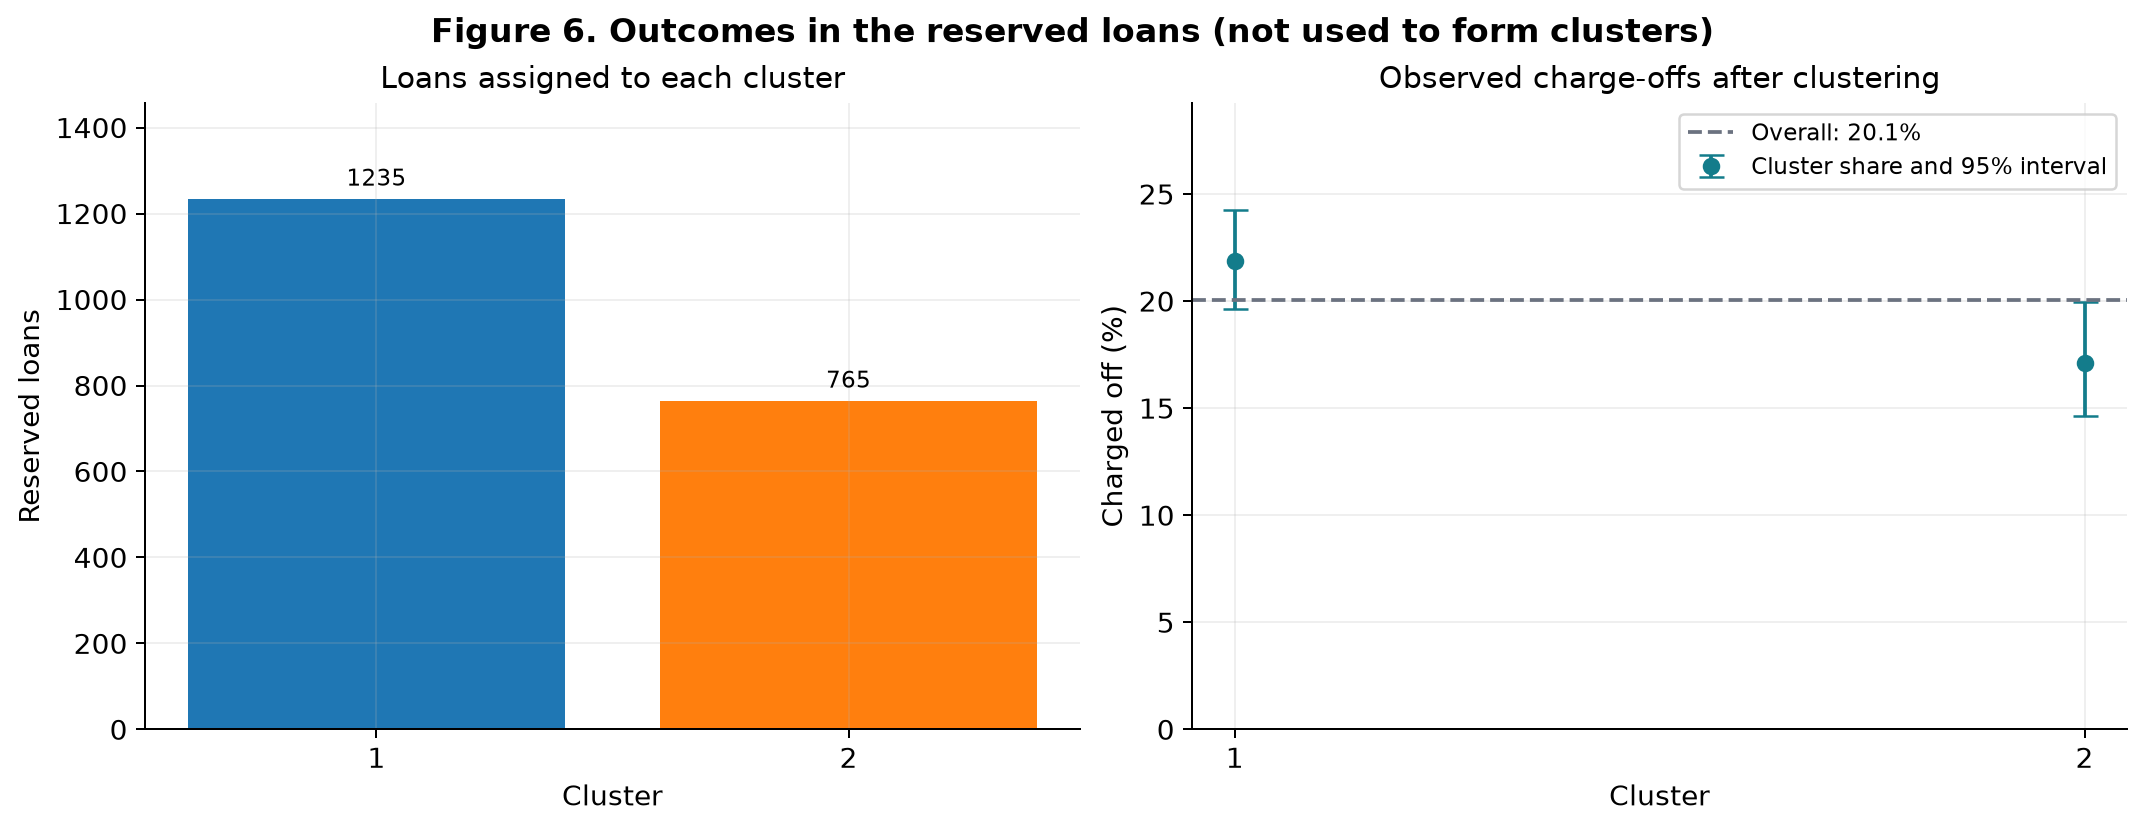

In [11]:
observed_check = study.loc[X_check.index, "loan_status"].map({"Fully Paid": 0, "Charged Off": 1}).astype(int)
outcome_frame = X_check.assign(Cluster=check_labels+1, charged_off=observed_check)
outcome_profile = outcome_frame.groupby("Cluster").charged_off.agg(Loans="size", Charged_off="sum")
outcome_profile = outcome_profile.reindex(range(1, selected_k+1), fill_value=0)
outcome_profile["Charge-off share"] = outcome_profile.Charged_off.div(outcome_profile.Loans.replace(0, np.nan))

# Wilson binomial interval, using z = 1.96 for approximately 95% coverage.
n = outcome_profile.Loans.replace(0, np.nan).to_numpy(dtype=float)
p = outcome_profile["Charge-off share"].to_numpy(dtype=float)
z = 1.96
denominator = 1 + z*z/n
center = (p + z*z/(2*n))/denominator
half_width = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/denominator
outcome_profile["Lower 95%"] = center-half_width
outcome_profile["Upper 95%"] = center+half_width
show_table(outcome_profile.reset_index(), 4)
reserved_medians = outcome_frame.groupby("Cluster")[CLUSTER_FEATURES].median()
show_table(reserved_medians.reset_index(), 2)
outcome_profile.to_csv(OUTPUT_DIR / "reserved_outcome_profiles.csv")
reserved_medians.to_csv(OUTPUT_DIR / "reserved_feature_medians.csv")
pd.DataFrame({"source_row": study.loc[X_check.index, "source_row"].to_numpy(),
    "cluster": check_labels+1, "observed_charged_off": observed_check.to_numpy()
}).to_csv(OUTPUT_DIR / "reserved_cluster_assignments.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.5), layout="constrained")
groups = outcome_profile.index.to_numpy()
bars = axes[0].bar(groups, outcome_profile.Loans, color=[COLORS[g-1] for g in groups])
axes[0].bar_label(bars, padding=3, fontsize=9)
axes[0].set(title="Loans assigned to each cluster", xlabel="Cluster", ylabel="Reserved loans",
            xticks=groups, ylim=(0, max(1, outcome_profile.Loans.max())*1.18))
present = outcome_profile.loc[outcome_profile.Loans.gt(0)]
errors = np.vstack([present["Charge-off share"]-present["Lower 95%"],
                    present["Upper 95%"]-present["Charge-off share"]])
axes[1].errorbar(present.index, present["Charge-off share"]*100, yerr=np.maximum(errors, 0)*100,
                 fmt="o", color=TEAL, capsize=5, label="Cluster share and 95% interval")
axes[1].axhline(observed_check.mean()*100, color=GRAY, ls="--", label=f"Overall: {observed_check.mean():.1%}")
axes[1].set(title="Observed charge-offs after clustering", xlabel="Cluster", ylabel="Charged off (%)",
            xticks=groups, ylim=(0, min(100, max(10, float(present['Upper 95%'].max()*100)+5))))
axes[1].legend(fontsize=9)
fig.suptitle("Figure 6. Outcomes in the reserved loans (not used to form clusters)", fontweight="bold")
finish(fig, "figure_6_reserved_outcomes")

### What I learned from this run
The main thing I learned is that K-means can divide the loans into groups without giving me a clear answer about how many borrower types exist. Silhouette selected k = 2, with a mean score of 0.219 across the 1,000 sampled fitting loans. The elbow calculation pointed to k = 3. I kept k = 2 because silhouette was my selection rule, but I would not describe that choice as obvious.

The silhouette lead over the next setting was 0.031, and 11.0% of the evaluated fitting loans had negative silhouette values. Those loans were closer, on average, to another group than to their assigned one. The reserved-loan silhouette was 0.229. Taken together, these results give me a reason to describe the groups cautiously. They do not show sharply separated borrower categories.

Scaling changed the groups considerably. Compared with the main model, which logged the dollar features and then standardized all six features, the original-units grouping had an adjusted Rand index of −0.020. Standardization without the log step gave 0.423. Since ARI measures agreement between partitions, these results show how much the answer depends on how I represent the loans. They do not tell me which version predicts repayment better.

The grouping changed less when I kept the representation fixed. Across three different initialization seeds, agreement on the reserved loans ranged from 0.935 to 0.990. Refitting preprocessing and K-means on three 80% subsets gave ARIs from 0.893 to 0.982. That is encouraging for these checks, although three runs on this dataset cannot tell me whether the same groups will hold up in a later lending period.

The largest fitting group, Cluster 1, contained 4,963 loans. Its median loan amount was $16,000, annual income was $74,000, DTI was 19.0, and FICO was 685. Those original unit summaries help me explain the group more easily than the transformed centers. The cluster number itself does not indicate risk. I also have to be careful with the PCA picture: its two displayed components retain 58.0% of the transformed feature variation, so the picture shows only part of the space used for clustering.

After fixing the groups, I compared repayment outcomes on the reserved loans. Cluster 1 had 1,235 loans and a 21.9% charge-off share. Cluster 2 had 765 loans and a 17.1% share. The gap calculated before rounding those percentages was 4.7 percentage points. The group sizes and confidence intervals matter when interpreting that difference.

For my capstone, this gives me another way to describe the borrowers and ask where the outcome differences come from. It does not show that a cluster label predicts an individual loan's outcome well, or that belonging to a group causes a charge-off. My next step would be to check whether similar profiles and outcome differences appear in loans issued later. I would use the groups to guide further analysis before considering whether they add anything to a risk model.

## Limits and next steps
K-means will form groups even when the data do not contain clear separation. It favors compact groups under squared Euclidean distance and may struggle with irregular shapes or very different densities. Large values can still pull the centers after scaling, especially in features I did not log. A high silhouette can also hide a small isolated group, which is why I report sizes and individual silhouettes.

The choice of six features is another limit. Related financial measures can give some information extra influence, and leaving out categorical features means this is only one view of the borrowers. I would compare a smaller feature set, additional outlier handling, and another clustering method using fitting data. I would keep those choices separate from the charge-off labels.

The silhouette is estimated on a subset, and I only test k = 2 through 8 for selection. Three seed checks and three smaller-sample checks do not measure all the uncertainty. The reserved sample is a random split of historical accepted loans, so it is a check on this dataset rather than evidence that the same grouping will work in a later lending period. Reusing it repeatedly could also influence later choices.

Before carrying the result further, I would check later-issued loans, possible borrower overlap, and whether group differences remain after accounting for issue date and other characteristics. I would also examine whether the groups lead to unfair assumptions about borrowers. Clustering can help organize the analysis, but it does not replace a validated risk model or a review of individual circumstances.

## References

Scikit-learn developers. (n.d.-a). Clustering: K-means. scikit-learn. https://scikit-learn.org/stable/modules/clustering.html#k-means

Scikit-learn developers. (n.d.-b). KMeans. scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html

Scikit-learn developers. (n.d.-c). Selecting the number of clusters with silhouette analysis on KMeans clustering. scikit-learn. https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html

Scikit-learn developers. (n.d.-d). Silhouette_score. scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html

Scikit-learn developers. (n.d.-e). StandardScaler. scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

Wordsforthewise. (n.d.). All Lending Club loan data (Version 3) [Data set]. Kaggle. https://www.kaggle.com/datasets/wordsforthewise/lending-club